# E93: Does least squares keep Qwen3-1.7B's decomposition faithful on every saved fine-tune?

**The answer.** Not on every fine-tune, so by its filed rule least squares fails this table. On the template fine-tune, the TOFU facts fine-tune and both supervised maths fine-tunes it passes every check at every seed. It misses narrowly on the three small reinforcement-learning maths updates: one RL seed on the clean model and under masks, the shuffled-reward arm on the share left in Δ, and the own-samples arm on both. The misses are tiny in nats, but a filed miss stands. We had leaned towards a pass everywhere, and that lean reversed.

*Amendment 1, at the end, puts the scaled adjoint split on the same table: it fails all eleven states. Provisional: no independent check. Full record: `reports/analyses/2026-11-06_analysis_e93-d1-table.md`.*


## What we were trying to test

The project asks whether a parameter decomposition can follow a fine-tune of its model and stay interpretable. Here the model is Qwen3-1.7B, called W0 when unchanged. Its decomposition writes every weight matrix as a sum of rank-one subcomponents $UV^\top$ plus a leftover term Δ. A small network Γ decides at each position which subcomponents to keep, and those choices are the masks. A fine-tune adds an update $\delta W$. The question here is whether one simple map can move the subcomponents so that they carry the fine-tuned model, instead of leaving the update in Δ.

The map is the **least-squares split**: the least-norm $(dU, dV)$ with $dU\,V^\top + U\,dV^\top \approx \delta W$. The **moved part** is $U'V'^\top - UV^\top$, what the subcomponents hold after the split. Whatever of $\delta W$ the moved part misses goes to Δ, so the full weights still equal the fine-tuned model. The reference is **do-nothing**: all of $\delta W$ goes into Δ and the subcomponents stay as they were. Do-nothing is trivially faithful, and it is the map the project has to beat.

We split the full update of every saved fine-tune, eleven states in seven arms:

- the **template** fine-tune, two seeds, which teaches a fixed answer format;
- the **TOFU facts** fine-tune, two seeds, which teaches made-up author facts and is about 37 times larger than the template update;
- **RL**: GRPO on GSM8K maths, two seeds;
- **shuffled-reward RL**, two seeds: the same training with the rewards shuffled, a null arm that moves the weights without a real signal;
- **own-samples SFT**, one seed: fine-tuning on the model's own sampled maths answers;
- two **supervised maths fine-tunes**, one seed each: the first one we ran, and one on gold answers.

Each state goes through four checks, each with a line filed before the run:

1. **The clean model.** Run W0 plus the moved part with no masks, and compare it with the fine-tune by $K = \mathrm{KL}(\text{fine-tune}\,\|\,\text{read})$, in nats per token position, averaged over every position of the arm's rows. Divide by the same K for W0 itself, which is the whole effect of the update. 0 means the moved part reproduces the fine-tune; 1 means it does nothing. The line is 0.02. A random change of the same size per matrix must read near 1, or the check has no teeth.
2. **The share left in Δ**: $\|\delta W - \text{moved}\|^2 / \|\delta W\|^2$, squared Frobenius norms summed over the 196 decomposed matrices. Do-nothing reads 1. Its null is the share that a random update of the same per-matrix sizes would leave, worked out exactly from the subcomponents' ranks. The line asks for the share to sit below the null by more than the difference in share between the arm's two seeds.
3. **Behaviour kept, clean.** Behaviour is the mean loss on answer tokens of held-out rows, scaled so that W0 reads 0 and the fine-tune 1. An arm is **graded** when a tenth of its update keeps at most half the behaviour. On a graded arm the moved part must keep at least as much as half the update does.
4. **Under the state's own masks.** Γ reads the new weights and picks masks. We compare K for least squares and for do-nothing under those masks. The line: least squares may be worse by at most twice the half-width of a bootstrap over rows.

Two more filed checks sit in the scorecard. The squared size of the moved part is about one minus the share, so it cannot fail least squares. Behaviour kept under masks read "no room" wherever it applied, because do-nothing's masks already keep nearly as much as the ceiling.

**What a pass would not show.** Not that the update sits on the right subcomponents: no check here fails a wrong placement inside the span. Not that VPD's adversarial masks would pass it, since no adversary ran. The masked check passes do-nothing by construction, so it can penalise harm but cannot credit a placement.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_d1_table")
T = json.loads((ROOT / "results" / "table.json").read_text())
S = T["states"]
missed = lambda s: ", ".join(k for k, r in s["rules"].items() if r["result"] in ("misses", "fails")) or "none"
lines = ["| state | arm | verdict | checks missed |", "|---|---|---|---|"]
lines += [f"| {n} | {s['arm']} | {s['verdict']} | {missed(s)} |" for n, s in S.items()]
display(Markdown(f"Table verdict: **{T['table']}**\n\n" + "\n".join(lines)))


Table verdict: **fails**

| state | arm | verdict | checks missed |
|---|---|---|---|
| a1_s0 | anchor 1 | passes | none |
| a1_s1 | anchor 1 | passes | none |
| a2_s42 | anchor 2 | passes | none |
| a2_s142 | anchor 2 | passes | none |
| R_s0 | RL | passes | none |
| R_s70 | RL | fails | 1, 5 |
| N_s0 | null | fails | 2 |
| N_s70 | null | fails | 2 |
| F_s0 | own-samples | fails | 2, 5 |
| u1 | u1 | passes | none |
| u2 | u2 | passes | none |

## What we expected, and why

On the first maths fine-tune, at step 10, least squares had left 0.090 of the update in Δ and reproduced the fine-tune closely on the clean model. Nothing in the earlier reads said a larger or a different update would behave differently, so we leaned towards a pass everywhere:

- The squared size would hold everywhere, near 0.91, because it is about one minus the share.
- The share would sit below its null at every state.
- The clean check would pass everywhere. RL seed 0 was the tight one: an earlier read of the same file gave 0.018 against the 0.02 line, and we said in advance that a miss there would stand.
- Under masks, least squares would be no worse than do-nothing.
- Only the TOFU facts update would read graded, since an earlier read found that a tenth of the first maths fine-tune already keeps 0.93 of its gain.
- Behaviour under masks would have no room on TOFU facts, as on every maths fine-tune before.
- So least squares would pass the table. That was a lean, not a strong prediction.


### Does the clean model still act like the fine-tune once the update sits in the subcomponents?


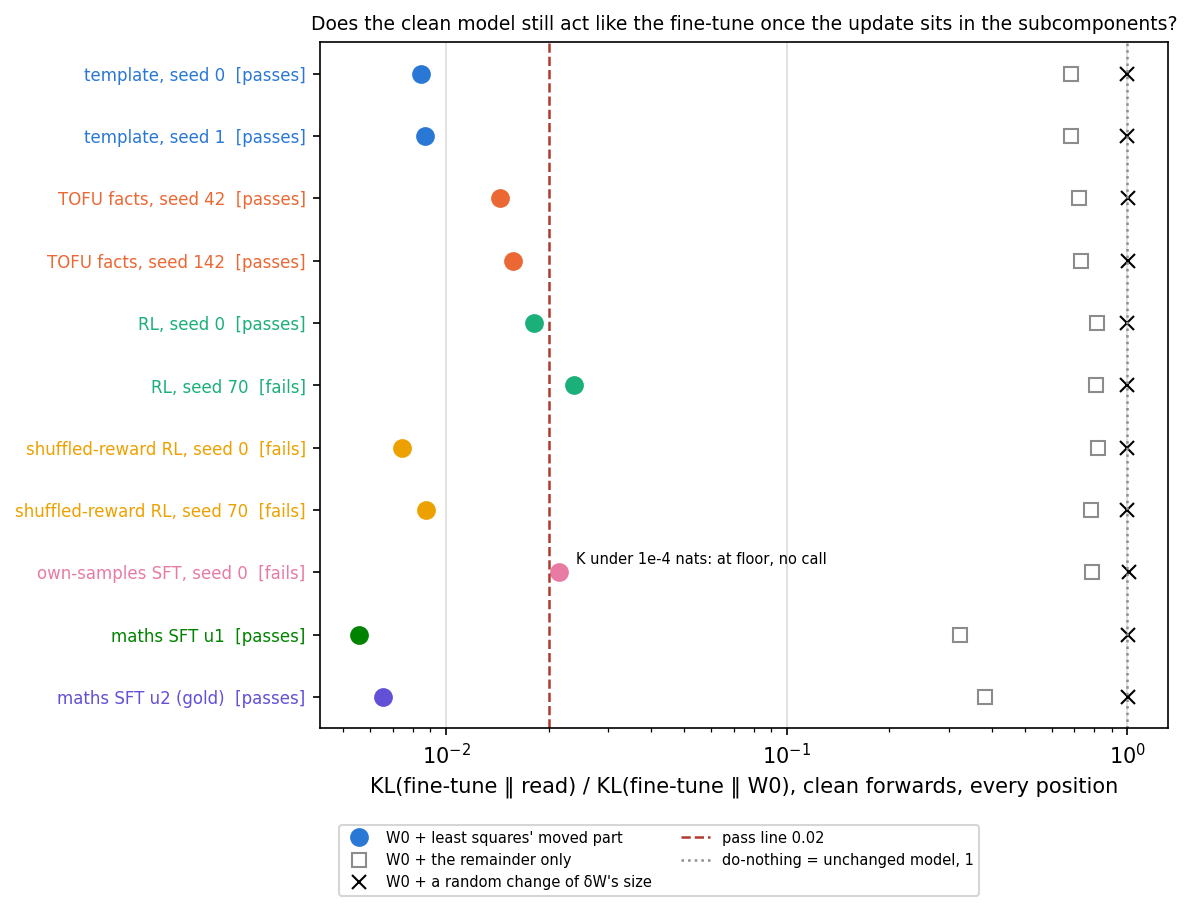

In [2]:
display(Image(ROOT / "figures" / "clean.png", width=850))


**Reading it.** Yes on ten of the eleven states, and narrowly no on RL seed 70. The filled dots are W0 plus the moved part, and everything left of the red dashed line passes. RL seed 70 reads 0.024 of the update's own effect against the line of 0.02. In nats, its moved part sits 0.0023 from the fine-tune where the line allows 0.0020, on an arm whose whole update moves the model only 0.098. The own-samples update is so small, 0.001 nats in all, that its moved part falls under the floor of 0.0001 nats and gets no call. The check has teeth on every state: a random change of the same size reads 1, and the remainder alone reads 0.3 to 0.8.


### Does least squares leave less of the update in Δ than a random change would?


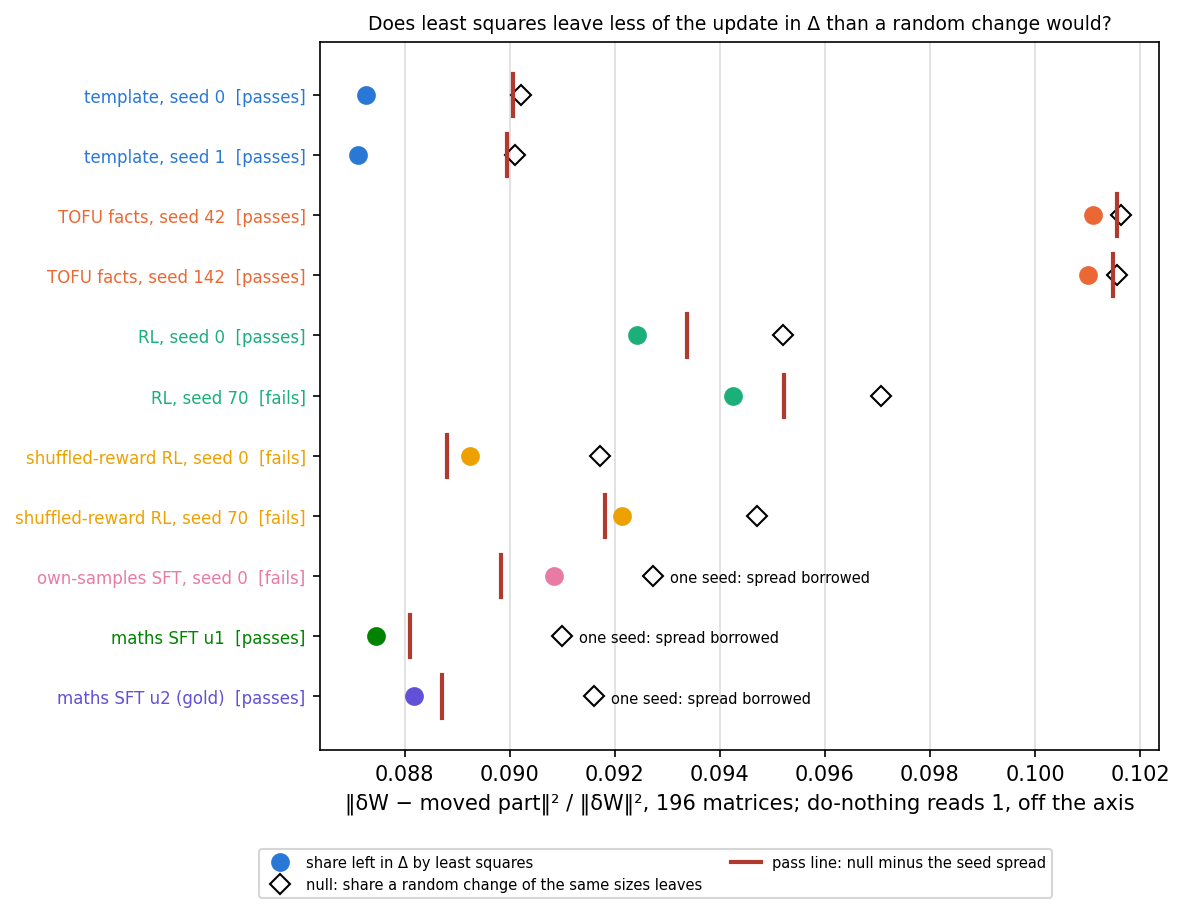

In [3]:
display(Image(ROOT / "figures" / "share.png", width=850))


**Reading it.** A little less on every state, but on three maths states not by enough to clear the line. Every dot sits left of its diamond, and the gap is small: about 3% of the null on most arms and half a percent on TOFU facts. The shuffled-reward arm misses at both seeds, with gaps of 0.0025 and 0.0026 against a seed spread of 0.0029. The own-samples arm has one seed, borrows that spread, and misses with a gap of 0.0019. The spread is large because the null itself moves by 0.003 between the two shuffled-reward seeds, while the gap moves by only 0.0001. The filed line compares the gap with the share's spread, and the misses stand. The caveat: about nine tenths of any update of these sizes already lies inside the subcomponents' span, so this check barely separates a real update from a random one.


### Does the moved part keep as much behaviour as half the update does?


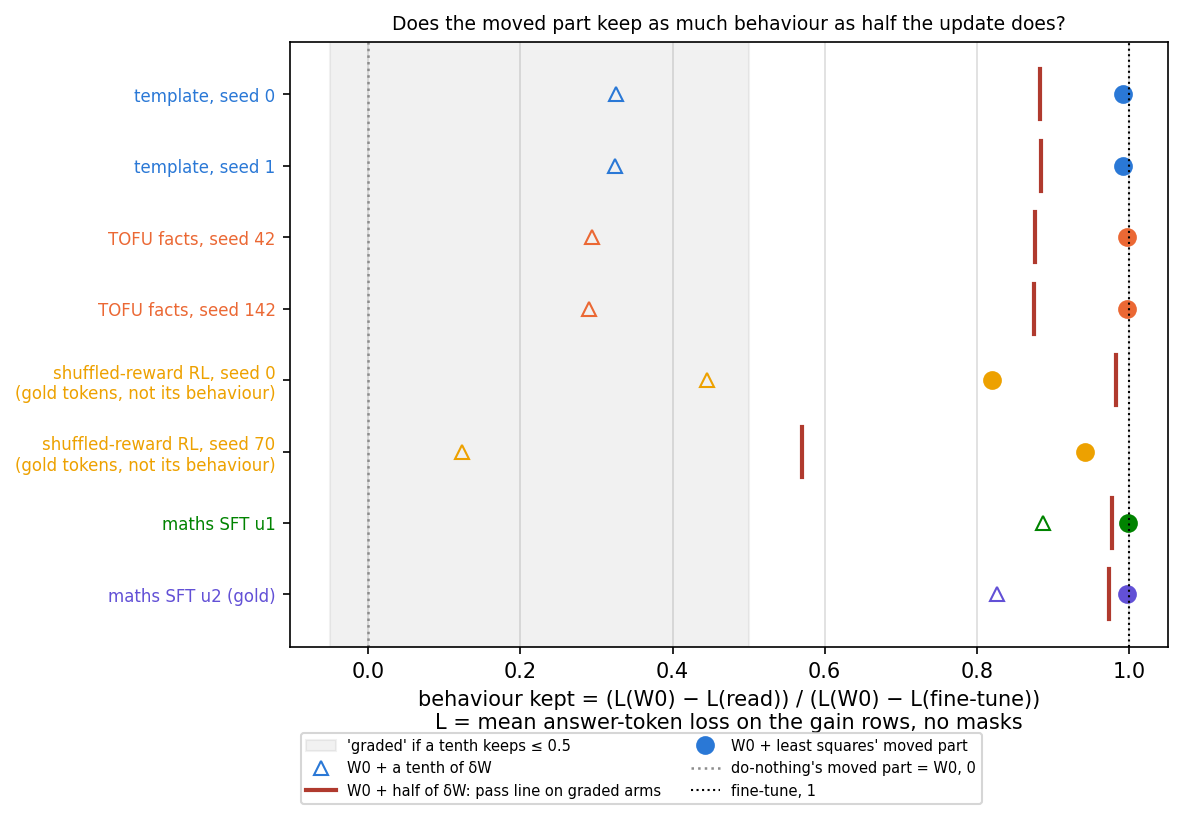

In [4]:
display(Image(ROOT / "figures" / "kept_clean.png", width=850))


**Reading it.** Yes, with room to spare, on every arm that has a behaviour to keep. On the template and TOFU facts fine-tunes the moved part keeps 0.99 to 1.00 of the gain, against about 0.88 for half the update. Both arms read graded, because a tenth of the update keeps only about 0.3, so the line could have failed them. We had expected only the TOFU facts update to read graded, and the template update builds with size too. The two supervised maths fine-tunes are not graded, since a tenth already keeps 0.83 to 0.89, and the check makes no call there. The shuffled-reward arm's gain on gold maths tokens also reads graded, but that gain is not what the arm was trained for and is not scored.


### Under its own masks, is least squares further from the fine-tune than doing nothing?


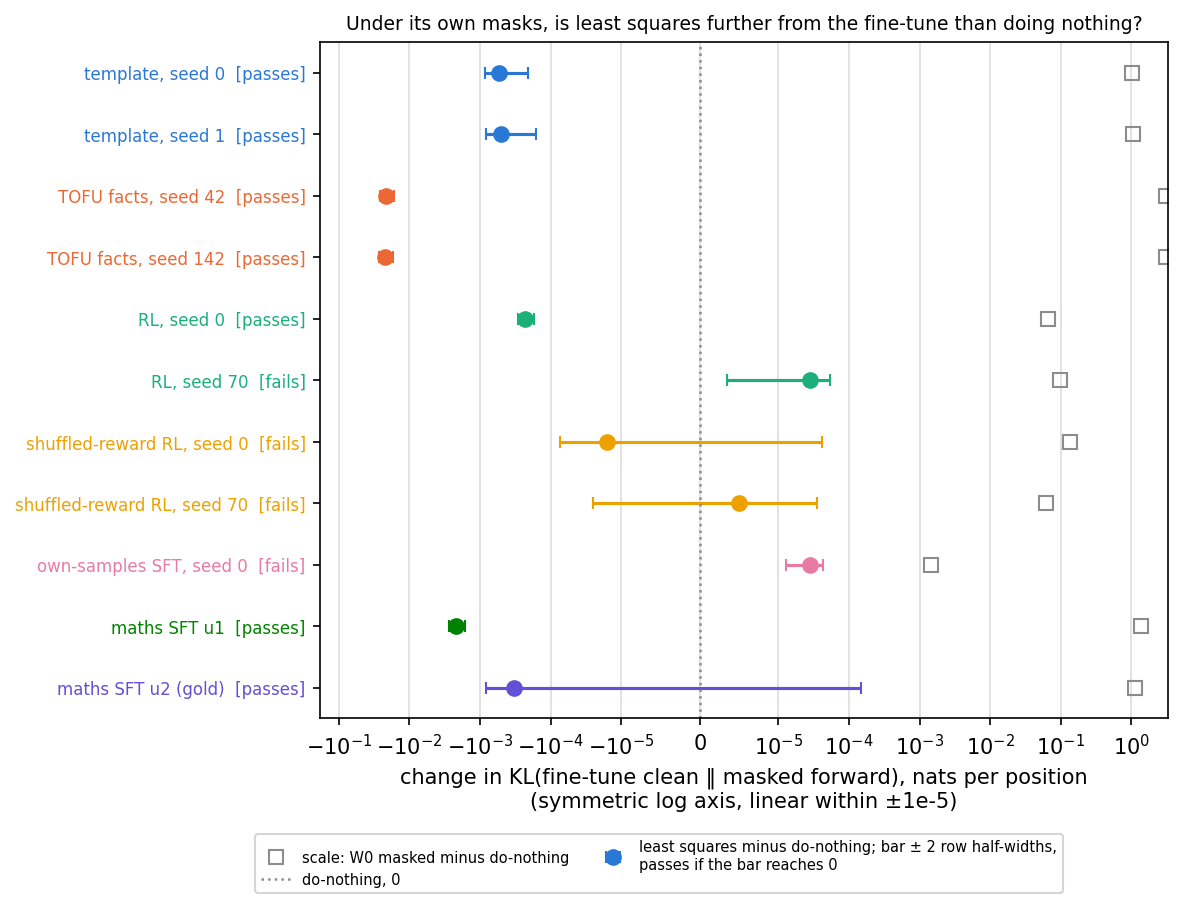

In [5]:
display(Image(ROOT / "figures" / "masked.png", width=850))


**Reading it.** No on nine states, and slightly yes on RL seed 70 and own-samples. On the template, TOFU facts and supervised maths fine-tunes least squares sits closer to the fine-tune than do-nothing, by 0.021 nats on TOFU facts. RL seed 70 is worse than do-nothing by 0.000029 nats against a line of 0.000025, and own-samples by 0.000028 against 0.000015. Against the grey squares, which show what the whole update does under masks, the RL miss is 0.03% of the update's effect and the own-samples miss about 2%. Both are some 2,400 times smaller than the decomposition's own masked error on these rows, 0.07 nats. They clear the row bootstrap's band, so by the filed rule they are not row noise, and they stand.


## What we learned

Least squares keeps the decomposition faithful by every filed check on the two updates the Qwen goal was framed on, the template and TOFU facts fine-tunes. That holds at both seeds, on a behaviour check that could have failed them. It also passes both supervised maths fine-tunes. The misses are all on the three small reinforcement-learning maths updates, whose whole effect on the model is 0.001 to 0.14 nats per position. There every line is relative to a tiny effect, and the misses are small in absolute terms, but the rules were filed that way and the table fails. The share left in Δ barely separates least squares from a random update on this decomposition, so a pass on it says little, and its misses here track the seed spread more than the map.


## How compelling is the evidence

- Four arms have two seeds. Own-samples and the two supervised maths fine-tunes have one, and borrow the shuffled-reward arm's seed spread for the share.
- Each arm is read on its own 128 rows of 256 tokens. Under masks, the template and TOFU facts arms are scored on answer positions whose question is in the same row, and the maths arms on every position.
- Noise: a bootstrap over rows for the clean and masked checks, the seed spread for the share. The decomposition's own masked error on maths rows is 0.07 nats, far above the masked differences read here.
- Blind spots: no check fails a wrong placement inside the span, no adversary ran, and the masked check passes do-nothing by construction.
- No independent check. Every control in the first stage reproduced its stored number to within a few parts in a million.


## Surprises

**Something unexpected happened that I cannot fully explain.** We leaned that least squares would pass every state, and it fails three maths arms. The misses are narrow, and on the share they come from the null itself moving between seeds, but the cause of the two masked misses is not named.

- The template update reads graded: a tenth of it keeps only 0.33 of its behaviour. We expected that only of TOFU facts.
- The shuffled-reward arm's gain on gold tokens also reads graded, though it is not scored.
- RL seed 0, the state we flagged as tight, passed at 0.018; its second seed missed instead.
- Printed and not scored: with masks chosen from W0's own forward, least squares keeps about 0.01 of the behaviour on the template and TOFU facts arms, and about 0.3 on the supervised maths ones. Do-nothing keeps 0 there by construction.


## What next

The filed plan says a failed table sends us to teacher training, which trains the subcomponents towards the fine-tuned model. But the amended plan aimed teacher training at TOFU facts, which passed here. Which update to aim it at is the user's open question:

- train towards the maths updates that missed: if it clears them, the trained map beats least squares where least squares fails;
- train towards TOFU facts as worded: this tests the trained map where least squares already passes, so it can at best tie;
- no teacher training: report this table as it reads and spend the days on the readings of what each update does inside the decomposition.

The lead recommends the first. The choice is the user's.


## Scorecard

| id | claim in words | rule | what was read | verdict |
|---|---|---|---|---|
| P1 | squared size at most 1 everywhere | ≤ 1 | 0.900 to 0.913 | holds |
| P2 | share below its null by more than the seed spread, everywhere | null − share > spread | shuffled-reward gaps 0.0025, 0.0026 vs 0.0029; own-samples 0.0019 vs 0.0029 | misses |
| P3 | clean under 0.02 of W0's K, or at floor, everywhere | ratio < 0.02 | RL seed 70: 0.0238; own-samples at floor | misses |
| P4 | masked K no worse than do-nothing by over twice the half-width | diff ≤ 2w | RL seed 70: 2.86e-5 vs 2.51e-5; own-samples 2.79e-5 vs 1.48e-5 | misses |
| P5 | of the arms with a behaviour line, only TOFU facts graded | tenth ≤ 0.5 | template graded too, 0.326 and 0.325 | misses |
| P6 | no room under masks on TOFU facts | room rule | ceiling − do-nothing 0.013 | holds |
| P7 | least squares passes every state, a lean | verdict | three arms fail | misses, reversed |


## Departures from the literature

- VPD scores a decomposition of a fixed model. Here Γ reads weights it was not trained on, and a map moves the subcomponents; VPD has no such procedure.
- VPD judges faithfulness by its own losses, adversarial masks among them. No adversary ran here: the user chose a table of clean, share, size and behaviour checks instead.
- The 0.02 clean line, the share's null and the masked line are this project's, not VPD's.
- GRPO's reward is answer accuracy. The gain on gold maths tokens read here is a different quantity, so the RL arms have no behaviour line.


## Not run

The adversary. Teacher training. Matched-size and intermediate-step states. The share weighted by inputs. The rarely-on and often-on halves. Accuracy under masks. A second seed for own-samples and the two supervised maths fine-tunes.

## Provenance

Code `experiments/qwen_d1_table/{run,rules,plot}.py`; plan `reports/plans/2026-11-05_plan_e93-d1-table.md`; filed rules `results/predictions.json`; results `results/table.json`, `results/<state>/state.json`, `results/run.log`. MATS cluster L40, jobs 52875 for the control, 52901 for TOFU facts, 53028 for the template and supervised maths, 53084 for the RL arms; about 4 h of card in all, $0. Peak card memory 42.5 GiB, host 95.6 GB.


---

# Amendment 1: does the scaled adjoint split clear the same table?

**The answer.** No. The scaled adjoint split fails D1's first table on all eleven states, as we leaned. Its state does most of what the fine-tune does but leaves a tenth to a third of it undone on the clean model, where the line allows a fiftieth. Two weak leans reversed: we expected it to hold more of a real update than of a random one, and to do no harm under its own masks. It did neither, on any state.

*Provisional: no independent check. Full record: the "Amendment 1" section of `reports/analyses/2026-11-06_analysis_e93-d1-table.md`.*

## What we were trying to test

The user asked for the adjoint split as a second column beside least squares. Everything in the table above is held fixed: the eleven full updates, their rows, the six rules and their thresholds, and every read that does not depend on the map. Only the map changes.

- **The scaled adjoint split** moves each matrix's subcomponents by $dU = c\,\delta W V$ and $dV = c\,\delta W^\top U$. Its weight change is $c\,K(\delta W)$, with $K(\delta W) = UU^\top\delta W + \delta W VV^\top$, plus the small second-order term $dU\,dV^\top$.
- **The scale** $c$ is fitted per matrix to match $\delta W$ in the input-weighted norm, with $\Sigma$ the input covariance at W0 over 128 maths rows. The same $\Sigma$ serves every arm.
- **Δ stays fixed.** What the map leaves out is dropped, not put into Δ. So the state is W0 plus the moved part, and its weights are not the fine-tuned ones.

Units, as above: K is KL(fine-tune clean ‖ read) in nats per position, natural log, not squared. The share and size are ratios of squared Frobenius norms over 196 matrices. Behaviour kept is a ratio of mean answer-token losses, 0 at W0 and 1 at the fine-tune.

A control ran first and alone on the first maths fine-tune's step 10. It reproduced do-nothing's and least squares' stored masked K, least squares' share, and an earlier run's clean K for the adjoint's first-order form, 0.16567 nats, to about one part in ten million.

## What we expected, and why

Strongly, that the adjoint misses the clean check everywhere, since its first-order form read 0.10 to 0.34 of the ruler before, and so that every arm fails. With medium confidence, that it fails the behaviour check on both example updates. Weakly, that it holds more of a real update than of a random change, since a fine-tune moves along high-variance inputs which $\Sigma$ weights. Weakly, that its own masks do no harm, as least squares' did on nine of eleven states.


### On the clean model, does the adjoint's moved part act like the fine-tune, as least squares' does?


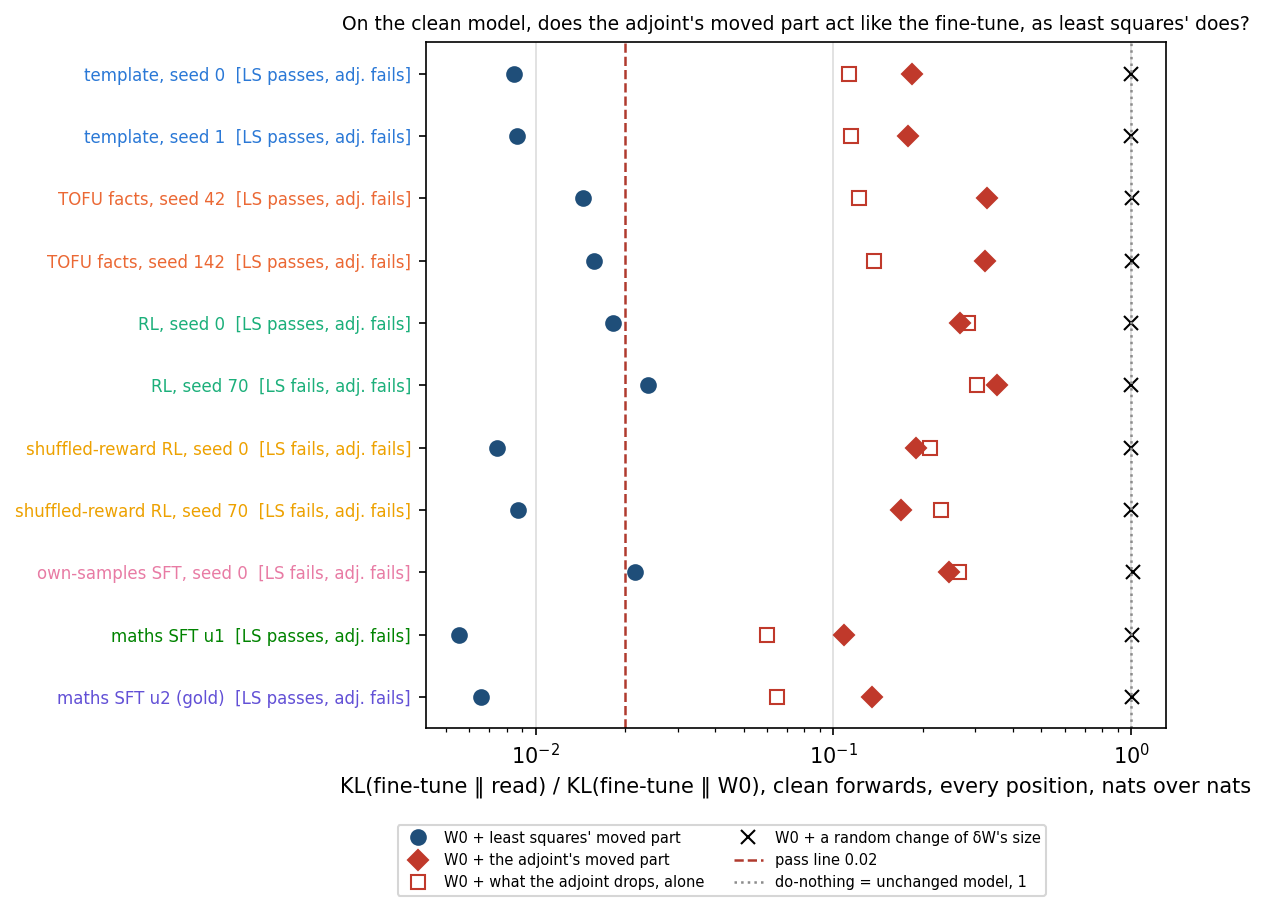

In [6]:
display(Image(ROOT / "figures" / "amend1_clean.png", width=850))


**Reading it.** No, on all eleven states and by a wide margin. The red diamonds, the adjoint's moved part, leave 0.11 to 0.35 of W0's distance to the fine-tune. The blue dots, least squares, leave 0.006 to 0.024, against the line at 0.02. The open squares are what the adjoint drops, applied alone: on most states they sit about as close to the fine-tune as what it keeps, and on the template and TOFU arms closer. Random changes of the same size read about 1, so the check has teeth.


### Does each map hold more of the real update than of a random change of the same sizes?


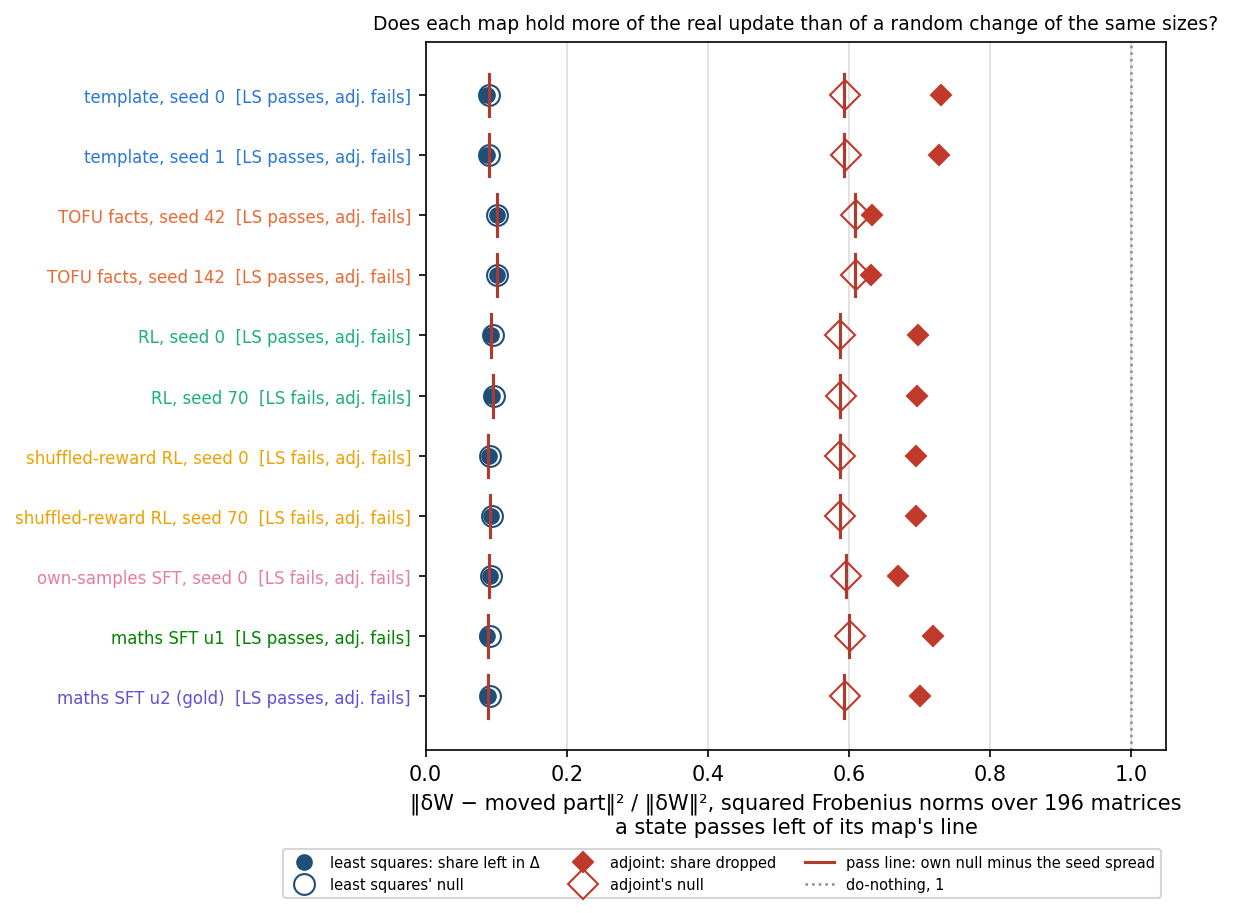

In [7]:
display(Image(ROOT / "figures" / "amend1_share.png", width=850))


**Reading it.** Least squares does, barely; the adjoint split does not, on any state, and this weak lean reversed. The adjoint drops 0.63 to 0.73 of the update's squared norm, right of its Gaussian null at 0.59 to 0.61. The excess is 0.02 on TOFU facts and 0.07 to 0.14 elsewhere, against seed spreads under 0.003. The rule weighs every weight entry equally, while the adjoint's scale is fitted on the input-weighted norm, where it reproduces 0.37 to 0.63 of the update. So the miss does not say which inputs the dropped part acts on, nor that the moved part sits on the wrong subcomponents. The cause is not named.

The squared size of the moved part is 0.36 to 0.74 of the update's, under the line at 1 on every state, as leaned.


### Does each map's moved part keep as much behaviour as half the update does?


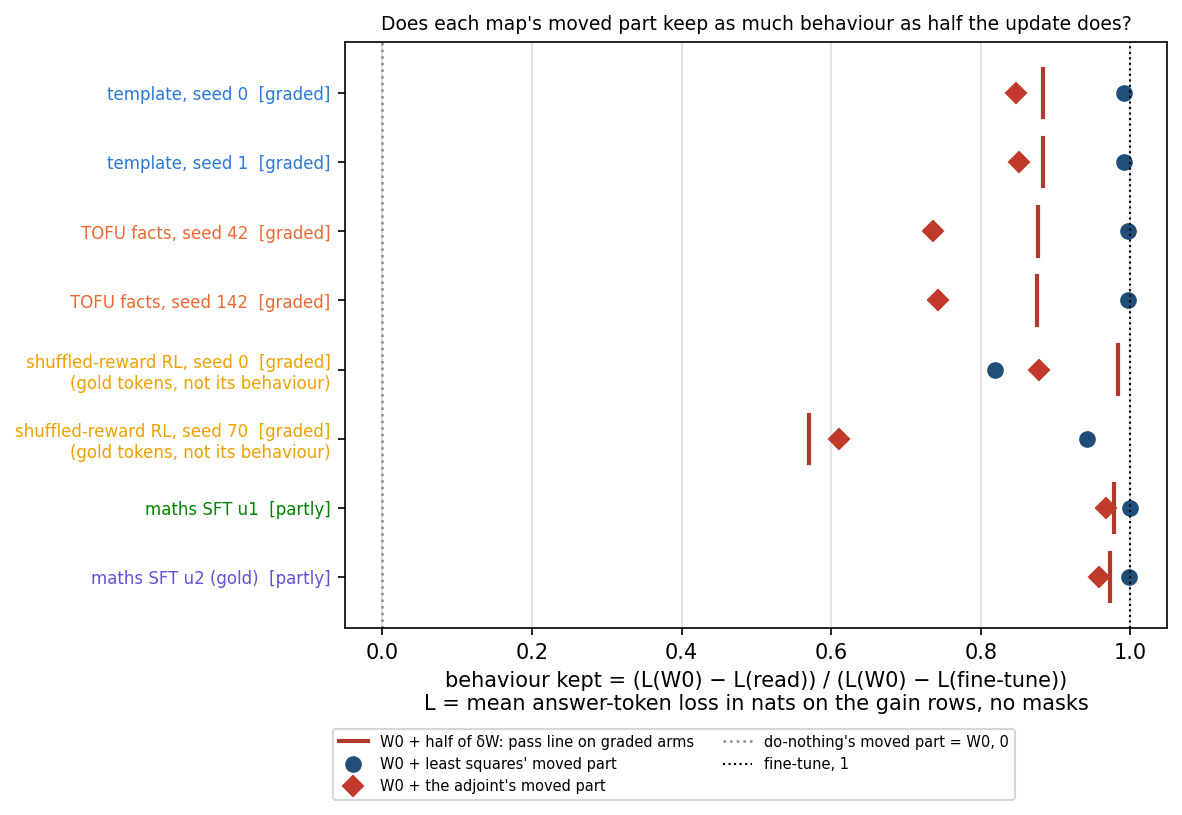

In [8]:
display(Image(ROOT / "figures" / "amend1_kept.png", width=850))


**Reading it.** Least squares does; the adjoint split does not on either example update, as leaned. On the template fine-tune the adjoint keeps 0.85 of the behaviour against a line of 0.88, and on TOFU facts 0.74 against 0.88. Least squares keeps 0.99 to 1.00 on both. On the supervised maths fine-tunes, which a tenth of the update already nearly saturates, the adjoint keeps 0.96 and 0.97, unscored. Kept under masks reads "no room" on both example updates, as for least squares, since its room depends only on the stored ceiling and do-nothing.


### Under its own masks, is each map further from the fine-tune than doing nothing?


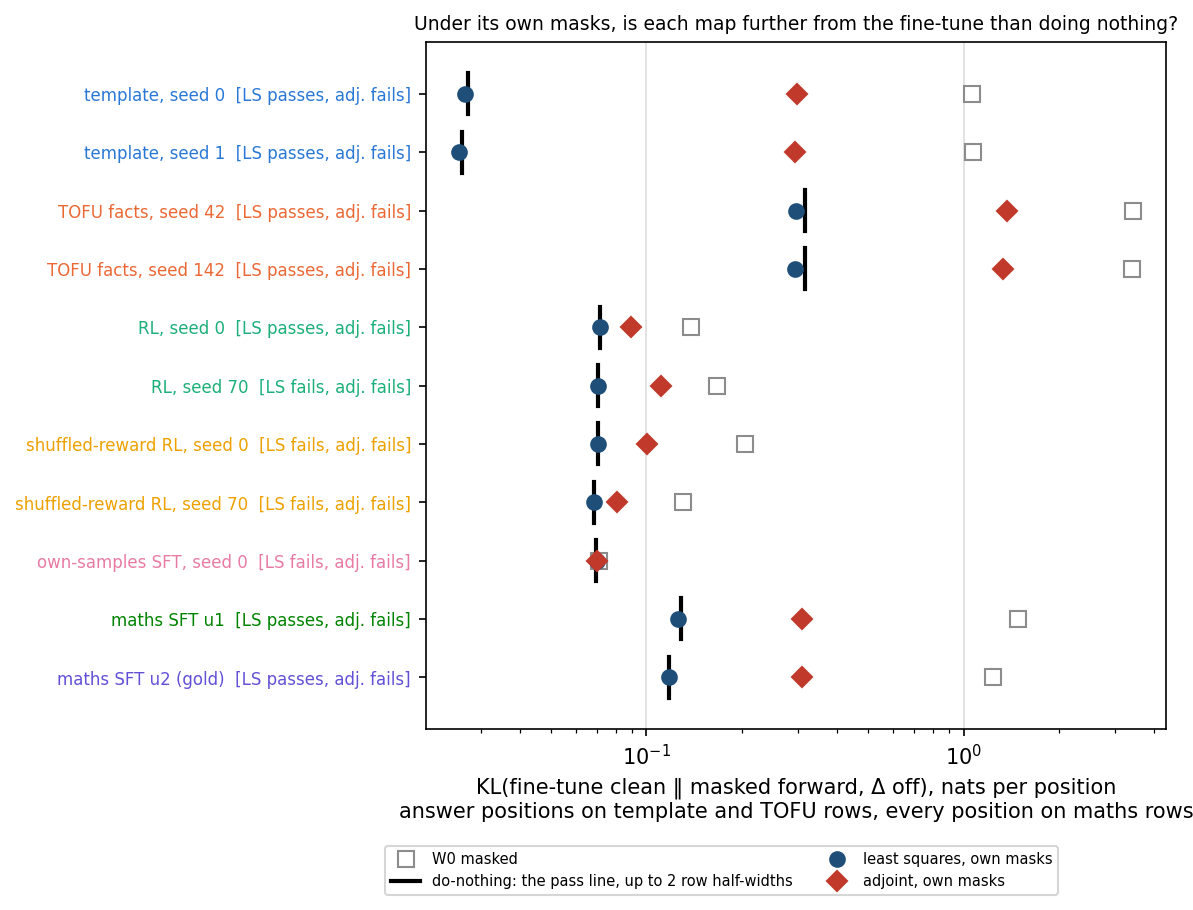

In [9]:
display(Image(ROOT / "figures" / "amend1_masked.png", width=850))


**Reading it.** The adjoint split is further from the fine-tune than doing nothing on every state, and this weak lean reversed. Its excess over do-nothing, the black bar, is 1.6 to 11 times the line. It is largest on TOFU facts, where the adjoint reads 1.37 nats per answer position against do-nothing's 0.32. Least squares sits on do-nothing's bar throughout. The check passes do-nothing by construction, so it can only penalise harm, never credit a placement. The adjoint still closes 0.66 to 0.87 of the gap between W0 masked, the grey squares, and do-nothing: a shortfall against a strong baseline, not a collapse.

## What we learned

The scaled adjoint split does not keep Qwen3-1.7B's decomposition faithful for any of the eleven saved updates, by the clean, share, behaviour or masked checks. Least squares, on the same rows and rules, misses only narrowly on three small reinforcement-learning arms. Of the two closed-form maps, least squares is the one to carry forward toward D1. The adjoint is a weak comparison column for teacher training: a trained map that beats it shows little.

## How compelling is the evidence

Most misses are several times their line; the narrowest is own-samples under masks, at 1.6 times. The map-free reads are the stored ones, checked by the control. One $\Sigma$, from maths rows, sets the scale on every arm, including the template and TOFU arms. The share is blind to inputs, the masked check cannot credit a placement, and no adversary ran. No independent check.

## Surprises

**Something unexpected happened that I cannot explain.** Two weak leans reversed on every state. We predicted the adjoint would drop less of a real update than of a random change; it drops more, by 0.02 to 0.14 of the squared norm. We predicted its own masks would do no harm; they leave it 0.0005 to 1.06 nats further from the fine-tune than do-nothing. The cause of neither is named. What the adjoint drops, applied alone, sits closer to the fine-tune than what it keeps on seven of eleven states.

## What next

- Teacher training runs on every arm with least squares as its comparison column, the adjoint beside it as the weaker baseline. A trained map that passes where least squares missed would change which map D1 uses.
- A per-arm $\Sigma$ for the template and TOFU arms, only if the adjoint is wanted at its best. A clean pass there would reopen it; another miss at 0.1 to 0.3 of the ruler closes it.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| A1_clean | misses everywhere | 0.109 to 0.353 of the ruler, line 0.02 | holds |
| A2_share | holds everywhere, weak | share above its null on all 11 | misses: lean reversed |
| A3_size | holds everywhere | 0.364 to 0.737, line 1 | holds |
| A4_kept_clean | fails on both example updates | 0.847 to 0.851 and 0.736 to 0.742 against about 0.88 | holds |
| A5_masked_K | holds everywhere, weak | 1.6 to 11 times the line on all 11 | misses: lean reversed |
| A6_no_room | no room on both example updates | no room | holds |
| A7_verdict | every arm fails, strong | all 11 fail | holds |

## Departures from the literature

As for least squares above. In addition: the adjoint split and its scale are this project's, from `GOALS.md` Terms, with no outside source; the second-order term is kept, unlike the earlier first-order form; and $\Sigma$ comes from maths rows for every arm, not each arm's own rows.

## Not run

The adjoint with a per-arm $\Sigma$. The adjoint with its dropped part put into Δ. The adversary. Either map's share weighted by inputs, as a rule. A second seed for own-samples and the two supervised maths fine-tunes. An independent check.

## Provenance

Code `experiments/qwen_d1_table/{amend1,rules,plot}.py`; filed leans `results/predictions_amend1.json`; results `results/amend1/{table.json,control.json,run.log,<state>.json}`. MATS cluster L40, `debug`: job 53914 the control; jobs 54583 and 54598 the template and TOFU arms, the first stopped by its time limit; job 54656 the maths arms. About 2.4 h of card, $0.
